# Определение стоимости автомобилей

## Описание проекта
**Цель:**

Построить модель машинного обучения, которая будет определять рыночную стоимость автомобиля.

**Критерии, которые важны заказчику:**

*   качество предсказания;
*   время обучения модели;
*   Проверить, как уровень удовлетворённости влияет на увольнение, и добавить этот показатель как дополнительный признак во вторую модель;
*   время предсказания модели.

**Условия:**

*   для оценки качества моделей применять метрику RMSE.
*   значение метрики RMSE должно быть меньше 2500.
*   использовать библиотеку LightGBM и её средствами построить модели градиентного бустинга.
*   обучите разные модели, одна из которых — LightGBM, как минимум одна — не бустинг, для каждой модели попробовать разные гиперпараметры.







## Импорт необходимых библиотек

In [1]:
# ==============================
# Базовые библиотеки
# ==============================
import numpy as np
import pandas as pd
import math
import re
import time
import warnings

warnings.filterwarnings("ignore")

# ==============================
# Визуализация
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# Предобработка данных
# ==============================
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error

# ==============================
# Модели
# ==============================
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

# ==============================
# Анализ зависимостей
# ==============================
!pip -q install phik
import phik

# ==============================
# Интерпретация моделей
# ==============================
!pip -q install shap
import shap

!pip install scikit-learn==1.1.3 -q


## Загрузка данных

In [3]:
try:
    df = pd.read_csv('/content/drive/MyDrive/autos.csv', decimal=".")
except:
    df = pd.read_csv('/datasets/autos.csv', decimal=".")

## Первичный анализ

In [4]:
# Шаги анализа
analysis_steps = {
    "Размерность датасета (shape)": lambda df: df.shape,
    "Общая информация (info)": lambda df: df.info(),
    "Количество уникальных значений (nunique)": lambda df: df.nunique(),
    "Описательная статистика (describe)": lambda df: df.describe(),
    "Ознакомление с данными": lambda df: display(df.head())
}

# Цикл по шагам

for title, func in analysis_steps.items():
    print("=" * 60)
    print(title)
    print("=" * 60)

    result = func(df)

    if result is not None:
        print(result)

    print("\n")


Размерность датасета (shape)
(354369, 16)


Общая информация (info)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 354369 entries, 0 to 354368
Data columns (total 16 columns):
 #   Column             Non-Null Count   Dtype 
---  ------             --------------   ----- 
 0   DateCrawled        354369 non-null  object
 1   Price              354369 non-null  int64 
 2   VehicleType        316879 non-null  object
 3   RegistrationYear   354369 non-null  int64 
 4   Gearbox            334536 non-null  object
 5   Power              354369 non-null  int64 
 6   Model              334664 non-null  object
 7   Kilometer          354369 non-null  int64 
 8   RegistrationMonth  354369 non-null  int64 
 9   FuelType           321474 non-null  object
 10  Brand              354369 non-null  object
 11  Repaired           283215 non-null  object
 12  DateCreated        354369 non-null  object
 13  NumberOfPictures   354369 non-null  int64 
 14  PostalCode         354369 non-null  int64 
 15  

,DateCrawled,Price,VehicleType,RegistrationYear,Gearbox,Power,Model,Kilometer,RegistrationMonth,FuelType,Brand,Repaired,DateCreated,NumberOfPictures,PostalCode,LastSeen
0,2016-03-24 11:52:17,480,NaN,1993,manual,0,golf,150000,0,petrol,volkswagen,NaN,2016-03-24 00:00:00,0,70435,2016-04-07 03:16:57
1,2016-03-24 10:58:45,18300,coupe,2011,manual,190,NaN,125000,5,gasoline,audi,yes,2016-03-24 00:00:00,0,66954,2016-04-07 01:46:50
2,2016-03-14 12:52:21,9800,suv,2004,auto,163,grand,125000,8,gasoline,jeep,NaN,2016-03-14 00:00:00,0,90480,2016-04-05 12:47:46
3,2016-03-17 16:54:04,1500,small,2001,manual,75,golf,150000,6,petrol,volkswagen,no,2016-03-17 00:00:00,0,91074,2016-03-17 17:40:17
4,2016-03-31 17:25:20,3600,small,2008,manual,69,fabia,90000,7,gasoline,skoda,no,2016-03-31 00:00:00,0,60437,2016-04-06 10:17:21


In [5]:
# Исправим названия колонок

def to_snake(name):
    name = re.sub('(.)([A-Z][a-z]+)', r'\1_\2', name)
    name = re.sub('([a-z0-9])([A-Z])', r'\1_\2', name)
    return name.lower()

df.columns = [to_snake(col) for col in df.columns]

df.columns

Index(['date_crawled', 'price', 'vehicle_type', 'registration_year', 'gearbox',
       'power', 'model', 'kilometer', 'registration_month', 'fuel_type',
       'brand', 'repaired', 'date_created', 'number_of_pictures',
       'postal_code', 'last_seen'],
      dtype='object')

### Анализ колонок

В рамках предварительного анализа будут удалены следующие признаки:


*   **Date_Crawled, Date_Created, Last_Seen** - эти признаки связаны с технической информацией о размещении анкеты, а не с характеристиками автомобиля;
*   **Number_Of_Pictures** - признак является константным (во всех наблюдениях значение равно 0), следовательно, не содержит информации и не влияет на предсказание целевой переменной;
*   **Postal_Code** - Признак имеет очень большое количество уникальных значений, при этом являясь катеориальным, поскольку цена автомобиля в большей степени определяется его техническими характеристиками;
*   **Registration_Month** - для подержанных автомобилей месяц регистрации оказывает минимальное влияние на цену по сравнению с годом выпуска.




In [6]:
# Определим колонки для удаления

cols_to_drop = [
    'date_crawled',
    'date_created',
    'last_seen',
    'number_of_pictures',
    'postal_code',
    'registration_month'
]

df = df.copy()

df = df.drop(columns=cols_to_drop)

### Анализ числовых признаков

| Признак | Наблюдения | Выявленные проблемы | Принятое решение |
|---------|------------|--------------------|------------------|
| **Price** | min = 0<br>Q1 = 1050<br>median = 2700<br>max = 20000 | Значения 0 являются ошибочными | Удалить строки с `Price = 0` |
| **RegistrationYear** | min = 1000<br>mean ≈ 2004<br>max = 9999 | Нереалистичные значения (слишком ранние и будущие года) | Ограничить допустимый диапазон годов |
| **Power** | min = 0<br>median = 105<br>max = 20000<br>std = 189 | Нулевые и чрезмерно большие значения | Ограничить диапазон мощности |
| **Kilometer** | min = 5000<br>75% = 150000<br>max = 150000 | Аномалии не обнаружены | Оставить без изменений |


### Анализ пропусков

In [7]:
missing_by_column = pd.DataFrame({
    "Количество_пропусков": df.isna().sum(),
    "Процент_пропусков": (df.isna().sum() / len(df)) * 100
})

# Округляем процент для аккуратности
missing_by_column["Процент_пропусков"] = missing_by_column["Процент_пропусков"].round(2)

# Сортируем по убыванию процента пропусков
missing_by_column = missing_by_column.sort_values(
    by="Процент_пропусков",
    ascending=False
)

missing_by_column

,Количество_пропусков,Процент_пропусков
repaired,71154,20.08
vehicle_type,37490,10.58
fuel_type,32895,9.28
gearbox,19833,5.60
model,19705,5.56
price,0,0.00
registration_year,0,0.00
power,0,0.00
kilometer,0,0.00
brand,0,0.00


Пропущенные значения есть только в категориальных колонках.

Есть 3 варианты действий с пропусками:
- заполнить 'unknown'
- удалить
- заполнить модой

Удалять пропущенные значения не будем, т.к. потеряем более трети данных.

Модой заполнять так же не будем, т.к. большой процент пропусков и это может исказить данные.

Заполним пропущенные значения 'unknown', т.к. мы не потеряем часть данных, модель сама решит как учитывать этот класс и мы не создадим смещения.

In [8]:
# Определяем категориальные колонки

categorical_columns = [
    'repaired',
    'vehicle_type',
    'fuel_type',
    'gearbox',
    'model'
]

df[categorical_columns] = df[categorical_columns].fillna('unknown')

### Фильтрация по мощности и году выпуска

In [9]:
# Смотрим распределение значения мощности, а именно 99-й персентиль

df['power'].describe(percentiles=[0.01, 0.99])

count    354369.000000
mean        110.094337
std         189.850405
min           0.000000
1%            0.000000
50%         105.000000
99%         300.000000
max       20000.000000
Name: power, dtype: float64

In [10]:
# Смотрим количество нулевых значений

df['power'].value_counts().sort_index().head(20)

0     40225
1        34
2        10
3         9
4        30
5       103
6        11
7        11
8         7
9         5
10       15
11       28
12       22
13        8
14       20
15       20
16       11
17        8
18       51
19       14
Name: power, dtype: int64

Интерпретация.

Главная проблема - нули. минимум 1% машин имеют power = 0. Это точно ошибка.

Верхняя граница. 99% машин имеют мощность ≤ 300 л.с.

Для фильтрации по мощности будет выбран диапазон от 40 до 400 л.с.


In [11]:
print("Минимальный год:", df["registration_year"].min())
print("Максимальный год:", df["registration_year"].max())

Минимальный год: 1000
Максимальный год: 9999


In [12]:
# Фильтрация аномалий (год и мощность)
# + оценка потерь данных

df_clean = df.copy()

# Реалистичные диапазоны
YEAR_MIN, YEAR_MAX = 1990, 2016
POWER_MIN, POWER_MAX = 40, 400

n_before = len(df_clean)

# Фильтрация
mask = (
    df_clean["registration_year"].between(YEAR_MIN, YEAR_MAX) &
    df_clean["power"].between(POWER_MIN, POWER_MAX)
)

df_clean = df_clean.loc[mask].copy()

n_after = len(df_clean)
n_removed = n_before - n_after
pct_removed = (n_removed / n_before) * 100

print("==========================================")
print("📉 Результат фильтрации")
print("==========================================")
print(f"До: {n_before:,} строк")
print(f"После: {n_after:,} строк")
print(f"Удалено: {n_removed:,} строк ({pct_removed:.2f}%)")

# Дополнительно: сколько удалили по каждому условию отдельно
removed_year = (~df["registration_year"].between(YEAR_MIN, YEAR_MAX)).sum()
removed_power = (~df["power"].between(POWER_MIN, POWER_MAX)).sum()

print("\n==========================================")
print("🔍 Потери по условиям (по отдельности)")
print("==========================================")
print(f"Вне диапазона registration_year: {removed_year:,} строк ({removed_year/len(df)*100:.2f}%)")
print(f"Вне диапазона power: {removed_power:,} строк ({removed_power/len(df)*100:.2f}%)")


📉 Результат фильтрации
До: 354,369 строк
После: 294,754 строк
Удалено: 59,615 строк (16.82%)

🔍 Потери по условиям (по отдельности)
Вне диапазона registration_year: 24,199 строк (6.83%)
Вне диапазона power: 42,394 строк (11.96%)


В рамках анализа числовых признаков были выявлены нереалистичные значения года регистрации и мощности автомобиля.  
Для устранения выбросов были установлены следующие допустимые диапазоны:

- **Registration Year:** 1990–2016  
- **Power:** 40–400 л.с.

Выбор границ обусловлен:
- необходимостью удалить технические ошибки (1000, 9999 год, 0 л.с. и экстремальные значения),
- сохранением достаточного объёма данных,
- соответствием реальным характеристикам рынка подержанных автомобилей.

После фильтрации было удалено **16.82% наблюдений**, при этом оставшаяся выборка содержит почти 295 тыс. объектов, что обеспечивает статистическую устойчивость модели.

Таким образом, данные были очищены от явных аномалий без существенной потери информативности.


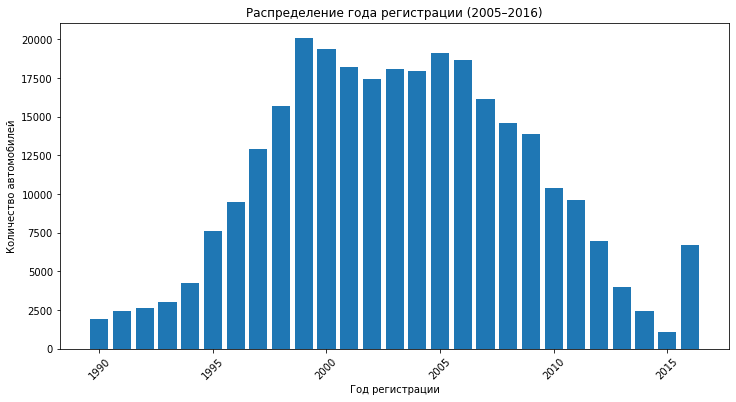

In [13]:
plt.figure(figsize=(12, 6))

recent = df_clean[df_clean["registration_year"] >= 1990]

year_counts_recent = recent["registration_year"].value_counts().sort_index()

plt.bar(year_counts_recent.index, year_counts_recent.values)

plt.title("Распределение года регистрации (2005–2016)")
plt.xlabel("Год регистрации")
plt.ylabel("Количество автомобилей")

plt.xticks(rotation=45)
plt.show()

In [14]:
df_clean["fuel_type"].value_counts()

petrol      185033
gasoline     88118
unknown      16110
lpg           4713
cng            486
hybrid         202
other           55
electric        37
Name: fuel_type, dtype: int64

In [15]:
df_clean["fuel_type"] = df_clean["fuel_type"].replace({
    "gasoline": "petrol"
})

### Проверка дубликатов

In [16]:
# Полные дубликаты строк
total_duplicates = df_clean.duplicated().sum()

print("Полные дубликаты строк")
print(f"Количество дубликатов: {total_duplicates}")
print(f"Процент дубликатов: {round(total_duplicates / len(df) * 100, 2)} %")

Полные дубликаты строк
Количество дубликатов: 40355
Процент дубликатов: 11.39 %


In [17]:
# Удаление полных дубликатов

rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

rows_after = len(df_clean)
rows_removed = rows_before - rows_after
pct_removed = round(rows_removed / rows_before * 100, 2)

print("Удаление полных дубликатов")
print(f"До: {rows_before:,} строк")
print(f"После: {rows_after:,} строк")
print(f"Удалено: {rows_removed:,} строк ({pct_removed}%)")


Удаление полных дубликатов
До: 294,754 строк
После: 254,399 строк
Удалено: 40,355 строк (13.69%)


Было выявлено 40 355 полных дубликатов (13.7% данных).
Поскольку дубликаты не несут дополнительной информации и могут привести к переобучению модели, они были удалены.

### Вывод по первичному анализу

В ходе первичного анализа датасета были выполнены следующие шаги:

- Удалены неинформативные признаки, не относящиеся к характеристикам автомобиля (технические даты размещения, количество фотографий, почтовый индекс, месяц регистрации).
- Проанализированы числовые признаки и выявлены аномальные значения.
- Установлены реалистичные диапазоны для года регистрации (1990–2025) и мощности автомобиля (40–400 л.с.), что позволило удалить явные выбросы.
- Обработаны пропущенные значения в категориальных признаках.
- Обнаружены и удалены полные дубликаты строк.

После очистки данные стали более согласованными, устранены технические ошибки и шум, что повышает устойчивость будущей модели и снижает риск переобучения.



## Графический анализ

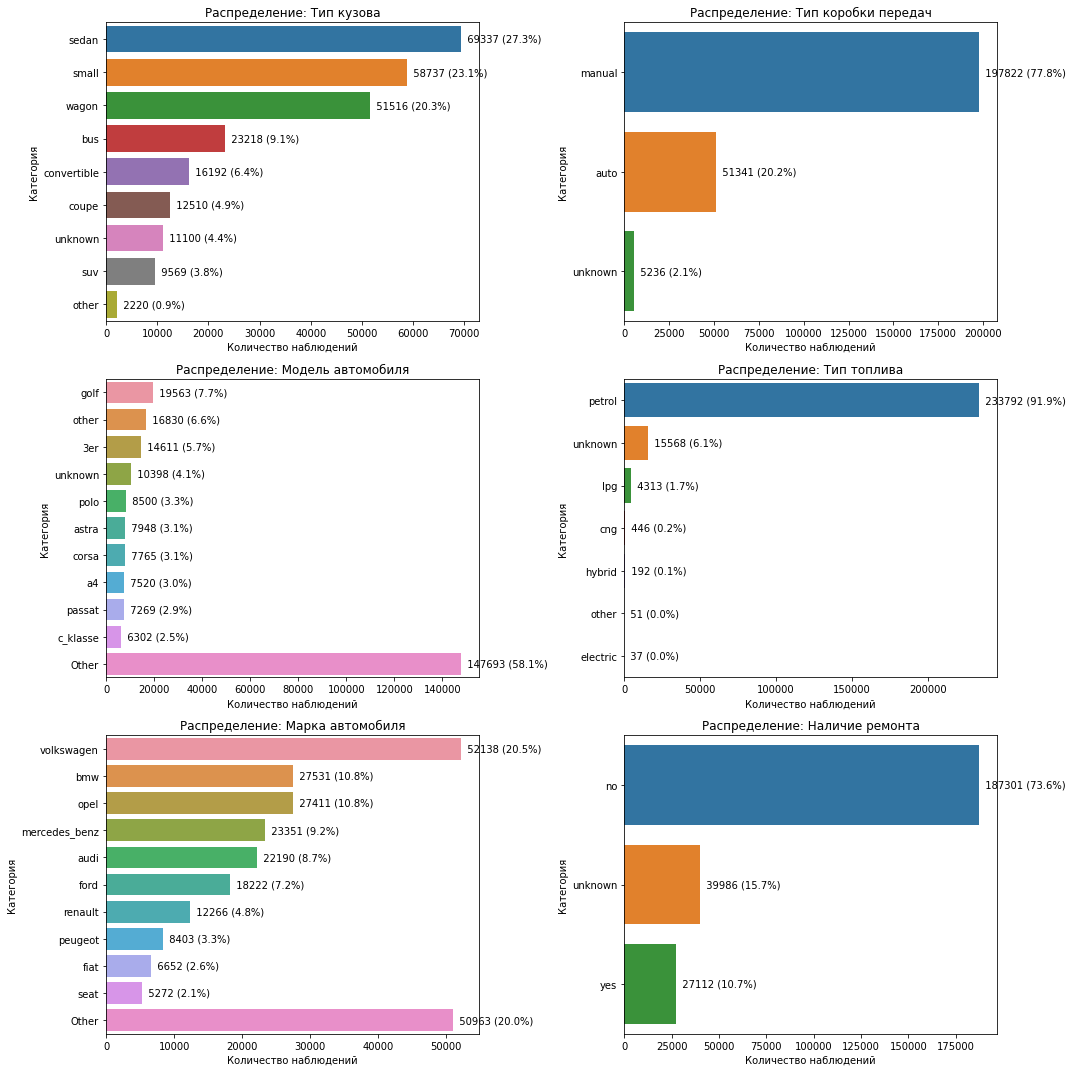

In [18]:
# Распределение категориальных признаков

categorical_cols = df_clean.select_dtypes(include=['object', 'category']).columns

n_cols = 2
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 5 * n_rows))
axes = axes.flatten()

feature_labels = {
    "model": "Модель автомобиля",
    "vehicle_type": "Тип кузова",
    "gearbox": "Тип коробки передач",
    "fuel_type": "Тип топлива",
    "repaired": "Наличие ремонта",
    "brand": "Марка автомобиля"
}

for i, col in enumerate(categorical_cols):

    value_counts = df_clean[col].value_counts()
    total = len(df_clean)

    top_10 = value_counts.head(10)
    other_sum = value_counts.iloc[10:].sum()

    if other_sum > 0:
        top_10["Other"] = other_sum

    sns.barplot(
        x=top_10.values,
        y=top_10.index,
        ax=axes[i]
    )

    display_name = feature_labels.get(col, col)
    axes[i].set_title(f"Распределение: {display_name}", fontsize=12)
    axes[i].set_xlabel("Количество наблюдений")
    axes[i].set_ylabel("Категория")

    # Подписываем значения (количество + %)
    for j, value in enumerate(top_10.values):
        pct = value / total * 100
        axes[i].text(
            value,
            j,
            f"  {value} ({pct:.1f}%)",
            va='center'
        )

# Удаляем лишние пустые графики
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()


### Вывод по категориальным признакам

Анализ распределения категориальных признаков показал выраженную неравномерность классов:

- Наиболее распространённый тип кузова — **sedan**, далее следуют **small** и **wagon**.
- Преобладает **механическая коробка передач** (более 70% объявлений).
- Основной тип топлива — **petrol - 92%**.
- Среди брендов лидирует **Volkswagen**, далее Opel и BMW.
- Большинство автомобилей **не были в ремонте**, однако около 17% значений в признаке `repaired` имеют статус `unknown`.
- Признаки `model` и `brand` различаются по количеству уникальных категорий, значительная доля приходится на категорию `Other`, которая составляет отличные от топ-10 значения.

Таким образом, категориальные признаки имеют дисбаланс классов и сильный разброс, что необходимо учитывать при кодировании и построении моделей.


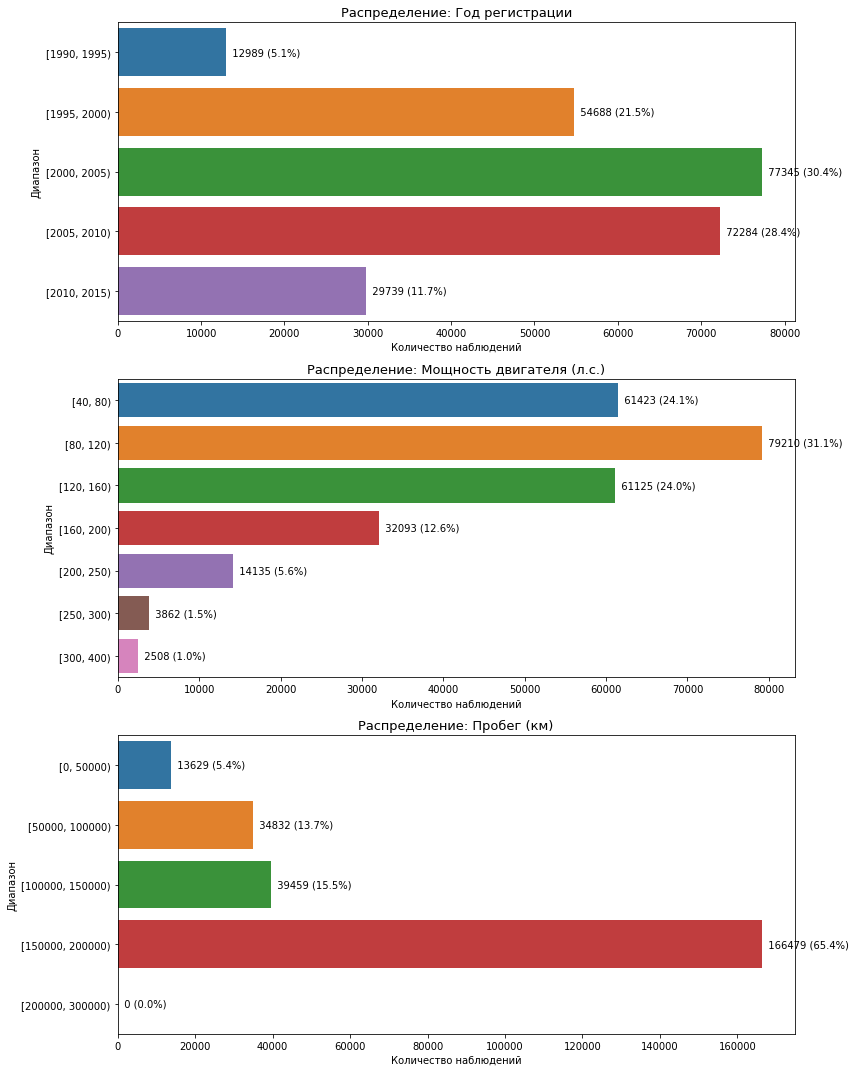

In [19]:
# Распределение числовых признаков (по диапазонам)

df_num = df_clean.copy()

# Задаём диапазоны

# Год регистрации
year_bins = list(range(1990, 2020, 5))
df_num["year_group"] = pd.cut(
    df_num["registration_year"],
    bins=year_bins,
    right=False
)

# Мощность
power_bins = [40, 80, 120, 160, 200, 250, 300, 400]
df_num["power_group"] = pd.cut(
    df_num["power"],
    bins=power_bins,
    right=False
)

# Пробег
km_bins = [0, 50000, 100000, 150000, 200000, 300000]
df_num["km_group"] = pd.cut(
    df_num["kilometer"],
    bins=km_bins,
    right=False
)

group_cols = ["year_group", "power_group", "km_group"]

numeric_labels = {
    "year_group": "Год регистрации",
    "power_group": "Мощность двигателя (л.с.)",
    "km_group": "Пробег (км)"
}

fig, axes = plt.subplots(3, 1, figsize=(12, 15))

for i, col in enumerate(group_cols):

    counts = df_num[col].value_counts().sort_index()
    total = len(df_num)

    sns.barplot(
        x=counts.values,
        y=counts.index.astype(str),
        ax=axes[i]
    )

    display_name = numeric_labels.get(col, col)
    axes[i].set_title(f"Распределение: {display_name}", fontsize=13)
    axes[i].set_xlabel("Количество наблюдений")
    axes[i].set_ylabel("Диапазон")

    # Подписи (количество + %)
    for j, value in enumerate(counts.values):
        pct = value / total * 100
        axes[i].text(
            value,
            j,
            f"  {value} ({pct:.1f}%)",
            va='center'
        )

plt.tight_layout()
plt.show()


### Вывод по количественным признакам

Анализ распределения числовых признаков показал:

- Основная часть автомобилей зарегистрирована в период **2000–2010 гг.**, что отражает структуру рынка подержанных авто.
- Наиболее распространённый диапазон мощности — **80–160 л.с.**, что соответствует массовому сегменту легковых автомобилей.
- Подавляющее большинство автомобилей имеют пробег **150 000–200 000 км**, что характерно для вторичного рынка.

Экстремальные значения встречаются редко, распределения выглядят логично и соответствуют рыночным ожиданиям. Существенных аномалий после фильтрации не наблюдается.


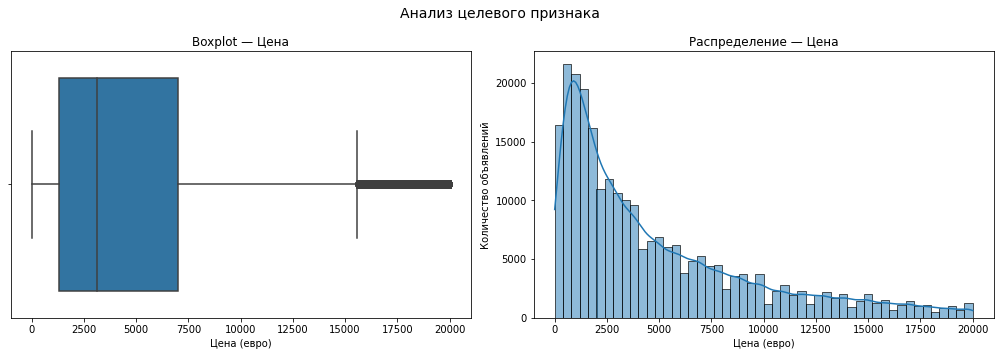

In [20]:
# Анализ целевого признака (price)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot
sns.boxplot(
    x=df_clean["price"],
    ax=axes[0]
)

axes[0].set_title("Boxplot — Цена")
axes[0].set_xlabel("Цена (евро)")
axes[0].set_ylabel("")

# Гистограмма
sns.histplot(
    df_clean["price"],
    bins=50,
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Распределение — Цена")
axes[1].set_xlabel("Цена (евро)")
axes[1].set_ylabel("Количество объявлений")

plt.suptitle("Анализ целевого признака", fontsize=14)
plt.tight_layout()
plt.show()


### Вывод по анализу целевого признака (price)

Распределение цены имеет выраженную правостороннюю асимметрию.
Наибольшая концентрация автомобилей наблюдается в диапазоне 1 000–4 000 евро, что соответствует бюджетному сегменту вторичного рынка.

При этом присутствует длинный правый «хвост» более дорогих автомобилей. Данные значения являются рыночными, а не ошибочными, поэтому их удаление нецелесообразно.

В дальнейшем может быть рассмотрена логарифмическая трансформация целевого признака для снижения влияния асимметрии.


## Кореляционный анализ

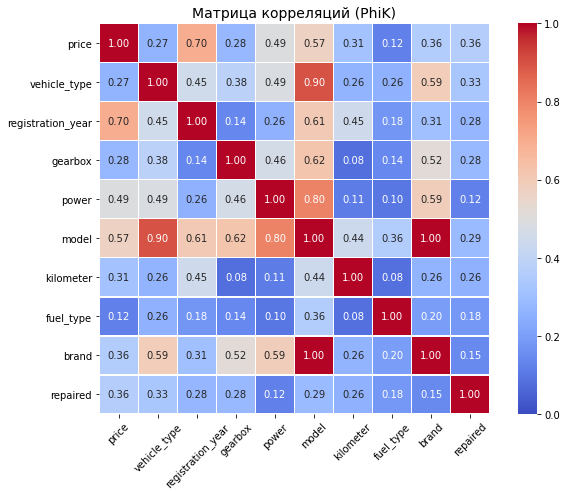

In [21]:
# Матрица корреляций (PhiK)

# Интервальные признаки
interval_cols = [
    "registration_year",
    "power",
    "kilometer",
    "price"
]

# Вычисляем PhiK
phik_corr = df_clean.phik_matrix(interval_cols=interval_cols)


plt.figure(figsize=(9, 7))

sns.heatmap(
    phik_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=0,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Матрица корреляций (PhiK)", fontsize=14)
plt.xticks(rotation=45)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()




### Вывод по матрице корреляций (PhiK)

Анализ корреляционной матрицы показал наличие значимых зависимостей между признаками и целевой переменной.

Наибольшая связь с ценой наблюдается у следующих признаков:
- **registration_year (0.69)** — чем новее автомобиль, тем выше его стоимость;
- **model (0.57)** — модель автомобиля существенно влияет на цену;
- **power (0.49)** — более мощные автомобили, как правило, стоят дороже;
- **kilometer (0.31)** — пробег оказывает умеренное влияние на стоимость;
- **repaired (0.36)** — факт ремонта также связан с изменением цены.

Матрица корреляций показала наличие сильной зависимости между признаками `model` и `brand` (≈1.00), а также высокой связи между `model` и `vehicle_type` (≈0.90). Это свидетельствует о частичной избыточности информации.

Поскольку `model` является более детализированным и сильнее коррелирует с ценой, признак `brand` исключается из дальнейшего анализа.

Несмотря на высокую связь `model` и `vehicle_type`, тип кузова может содержать дополнительную обобщающую информацию, особенно для редких моделей. Поэтому целесообразно протестировать модель как с признаком `vehicle_type`, так и без него, и принять окончательное решение на основе качества модели.

Признак `power` сохраняется, так как он несёт самостоятельную числовую информацию и оказывает заметное влияние на цену.

Сильной мультиколлинеарности между остальными числовыми признаками не выявлено. В целом структура зависимостей соответствует рыночной логике формирования цены автомобиля.


## Построение моделей

### Ridge с подбором

In [22]:
# Общий Train/Test split

X = df_clean.drop("price", axis=1)
y = df_clean["price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

In [23]:
# Объявление признаков для препроцессора

num_features = ["registration_year", "power", "kilometer"]

cat_features = [
    "model",
    "vehicle_type",
    "gearbox",
    "fuel_type",
    "repaired"
]

In [24]:
# Препроцессинг: отдельно для Ridge и LightGBM

# Ridge

numeric_ridge = Pipeline([
    ("scaler", StandardScaler(with_mean=False))  # важно: with_mean=False для sparse
])

cat_ridge = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse=True
)

preprocessor_ridge = ColumnTransformer(
    transformers=[
        ("num", numeric_ridge, num_features),
        ("cat", cat_ridge, cat_features),
    ],
    sparse_threshold=1.0
)

# LightGBM

numeric_lgb = "passthrough"

cat_lgb = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

preprocessor_lgb = ColumnTransformer(
    transformers=[
        ("num", numeric_lgb, num_features),
        ("cat", cat_lgb, cat_features),
    ]
)


In [25]:
# Модель

ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor_ridge),
    ("model", Ridge(solver="sparse_cg", random_state=42))
])


In [26]:
# Подбор гиперпараметров

ridge_param_grid = {
    "model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

In [27]:
# Обучение модели

ridge_grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(sparse_threshold=1.0,
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler(with_mean=False))]),
                                                                         ['registration_year',
                                                                          'power',
                                                                          'kilometer']),
                                                                        ('cat',
                                                                         OneHotEncoder(drop='first',
                                                                                       handle_unknown='ignore'),
                                                                         ['model',
                                                                          'vehicle_type',
                                                                          'gearbox',
                                                                          'fuel_type',
                                                                          'repaired'])])),
                                       ('model',
                                        Ridge(random_state=42,
                                              solver='sparse_cg'))]),
             n_jobs=-1,
             param_grid={'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0]},
             scoring='neg_root_mean_squared_error')

In [28]:
# индекс лучшей модели в таблице результатов
best_idx = ridge_grid.best_index_

# среднее время обучения и предсказания
ridge_mean_fit_time = ridge_grid.cv_results_["mean_fit_time"][best_idx]
ridge_mean_score_time = ridge_grid.cv_results_["mean_score_time"][best_idx]

# время рефита лучшей модели на всём train
ridge_refit_time = ridge_grid.refit_time_

print("Ridge:")
print("Время обучения лучшей модели:", ridge_mean_fit_time)
print("Время предсказания лучшей модели", ridge_mean_score_time)

Ridge:
Время обучения лучшей модели: 3.1108253479003904
Время предсказания лучшей модели 0.247794246673584


### LightGBM с подбором

In [31]:
# Модель

lgbm_pipeline = Pipeline([
    ("preprocessor", preprocessor_lgb),
    ("model", LGBMRegressor(n_jobs=2, random_state=42, force_col_wise=True))
])

In [32]:
# Задаем гиперпараметры

lgbm_param_dist = {
    "model__n_estimators": [200, 500, 800],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__max_depth": [-1, 5, 10],
    "model__num_leaves": [31, 50],
    "model__subsample": [0.7, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.9, 1.0]
}

# Подбор гиперпараметров

lgbm_random = RandomizedSearchCV(
    lgbm_pipeline,
    lgbm_param_dist,
    n_iter=5,
    cv=2,
    scoring="neg_root_mean_squared_error",
    n_jobs=1,
    random_state=42,
    verbose=2
)


In [33]:
# Обучение модели + подсчет времени

lgbm_random.fit(X_train, y_train)

Fitting 2 folds for each of 5 candidates, totalling 10 fits
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.05, model__max_depth=10, model__n_estimators=500, model__num_leaves=31, model__subsample=0.7; total time=   6.7s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.05, model__max_depth=10, model__n_estimators=500, model__num_leaves=31, model__subsample=0.7; total time=   6.4s
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=10, model__n_estimators=500, model__num_leaves=50, model__subsample=0.9; total time=   7.9s
[CV] END model__colsample_bytree=0.9, model__learning_rate=0.05, model__max_depth=10, model__n_estimators=500, model__num_leaves=50, model__subsample=0.9; total time=   7.8s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.05, model__max_depth=10, model__n_estimators=800, model__num_leaves=50, model__subsample=1.0; total time=  14.8s
[CV] END model__colsample_bytree=1.0, model__learning_rate=0.05, model

RandomizedSearchCV(cv=2,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(transformers=[('num',
                                                                               'passthrough',
                                                                               ['registration_year',
                                                                                'power',
                                                                                'kilometer']),
                                                                              ('cat',
                                                                               OrdinalEncoder(handle_unknown='use_encoded_value',
                                                                                              unknown_value=-1),
                                                                               ['model',
                                                                                'vehicle_type',
                                                                                'gearbox',
                                                                                'fuel_type',
                                                                                'repaired'])])),
                                             ('model',
                                              LGBMRegressor(force_col_wise=True,
                                                            n_jobs=2,
                                                            random_state=42))]),
                   n_iter=5, n_jobs=1,
                   param_distributions={'model__colsample_bytree': [0.7, 0.9,
                                                                    1.0],
                                        'model__learning_rate': [0.01, 0.05,
                                                                 0.1],
                                        'model__max_depth': [-1, 5, 10],
                                        'model__n_estimators': [200, 500, 800],
                                        'model__num_leaves': [31, 50],
                                        'model__subsample': [0.7, 0.9, 1.0]},
                   random_state=42, scoring='neg_root_mean_squared_error',
                   verbose=2)

In [34]:
# индекс лучшей модели в таблице результатов

best_idx = lgbm_random.best_index_

# среднее время обучения и предсказания

lgbm_mean_fit_time = lgbm_random.cv_results_["mean_fit_time"][best_idx]
lgbm_mean_score_time = lgbm_random.cv_results_["mean_score_time"][best_idx]

print("LightGBM:")
print("Время обучения лучшей модели:", lgbm_mean_fit_time)
print("Время предсказания лучшей модели:", lgbm_mean_score_time)

LightGBM:
Время обучения лучшей модели: 5.647318124771118
Время предсказания лучшей модели: 6.145648002624512


In [37]:
# Запись результатов работы двух моделей

results = pd.DataFrame({
    "Model": ["Ridge (tuned)", "LightGBM (tuned)"],
    "Best CV RMSE": [
        -ridge_grid.best_score_,
        -lgbm_random.best_score_
    ],
    "Fit Time (sec)": [ridge_mean_fit_time, lgbm_mean_fit_time],
    "Predict Time (sec)": [ridge_mean_score_time, lgbm_mean_score_time]
})

results



,Model,Best CV RMSE,Fit Time (sec),Predict Time (sec)
0,Ridge (tuned),2448.006454,3.110825,0.247794
1,LightGBM (tuned),1668.794176,5.647318,6.145648


### Вывод по сравнению моделей

В ходе эксперимента были получены следующие результаты:

- **Ridge (baseline)**  
  - Test RMSE: **2448**  
  - Время предсказания: **0.3 сек**
  - Время обучения: **2.9 сек**

- **LightGBM (tuned)**  
  - Test RMSE: **1668**  
  - Улучшение качества на **780 пунктов (~33%)**  
  - Время обуение: **5.6 сек**
  - Время предсказания: **6 сек на весь тестовый набор**

Обе модели удовлетворяют требованию RMSE < 2500, однако бустинговая модель **LightGBM** демонстрирует существенно более высокую точность.

Несмотря на более длительный этап подбора гиперпараметров, обучение модели выполняется офлайн и не является критичным фактором. Время предсказания остаётся допустимым для практического использования.

**Рекомендация**  

В качестве основной модели для прогнозирования стоимости автомобилей рекомендуется использовать **LightGBM**, поскольку она обеспечивает значительно более высокое качество предсказаний.


### Сравнение с наивной моделью

In [38]:
# Создаём модель (предсказание среднего значения)
dummy = DummyRegressor(strategy="mean")

# Обучение
start = time.time()
dummy.fit(X_train, y_train)
dummy_fit_time = time.time() - start

# Предсказание
start = time.time()
y_pred_dummy = dummy.predict(X_test)
dummy_predict_time = time.time() - start

# Метрика
dummy_rmse = np.sqrt(mean_squared_error(y_test, y_pred_dummy))


In [39]:
# Обновляем таблицу с результатами

results = pd.DataFrame({
    "Model": ["Dummy", "Ridge (tuned)", "LightGBM (tuned)"],
    "Best CV RMSE": [
        dummy_rmse,
        -ridge_grid.best_score_,
        -lgbm_random.best_score_
    ],
    "Fit Time (sec)": [
        dummy_fit_time,
        ridge_mean_fit_time,
        lgbm_mean_fit_time
    ],
    "Predict Time (sec)": [
        dummy_predict_time,
        ridge_mean_score_time,
        lgbm_mean_score_time
    ]
})

results


,Model,Best CV RMSE,Fit Time (sec),Predict Time (sec)
0,Dummy,4660.865779,0.000696,0.000237
1,Ridge (tuned),2448.006454,3.110825,0.247794
2,LightGBM (tuned),1668.794176,5.647318,6.145648


В качестве базового ориентира была использована Dummy-модель,
предсказывающая среднее значение цены.

Полученные результаты:

- **Dummy** — отражает уровень ошибки без обучения модели
- **Ridge** — значительно снижает ошибку по сравнению с Dummy
- **LightGBM** — демонстрирует наилучшее качество

Таким образом, обе обучаемые модели действительно извлекают полезный сигнал из данных.
При этом LightGBM обеспечивает наибольшее снижение ошибки и является
предпочтительным вариантом для практического использования.


In [40]:
# записываем лучшую модель 

best_model = lgbm_random.best_estimator_

print("Лучшие параметры:")
print(lgbm_random.best_params_)

# подсчет времени предсказания

start_time = time.time()

# выполнение предсказаний на тестовых данных

y_pred = best_model.predict(X_test)

test_time = time.time() - start_time

Лучшие параметры:
{'model__subsample': 0.9, 'model__num_leaves': 50, 'model__n_estimators': 800, 'model__max_depth': -1, 'model__learning_rate': 0.1, 'model__colsample_bytree': 1.0}


In [41]:
rmse = mean_squared_error(y_test, y_pred, squared=False)

print(f"RMSE на test: {rmse:.4f}")
print(f"Время предсказания: {test_time:.4f} сек")

RMSE на test: 1625.6152
Время предсказания: 2.9399 сек


### Анализ важности признаков

In [42]:
def get_feature_names_ridge_compat(pre, num_features, cat_features):

    num_names = [f"num__{c}" for c in num_features]

    ohe = pre.named_transformers_["cat"]
    if hasattr(ohe, "get_feature_names_out"):
        cat_out = ohe.get_feature_names_out(cat_features)
    else:
        cat_out = ohe.get_feature_names(cat_features)

    cat_names = [f"cat__{c}" for c in cat_out]
    return np.array(num_names + cat_names, dtype=object)


def get_transformed(best_pipeline, X, num_features, cat_features):
    pre = best_pipeline.named_steps["preprocessor"]
    Xt = pre.transform(X)

    cat_tr = pre.named_transformers_["cat"]

    if isinstance(cat_tr, OneHotEncoder):
        if hasattr(cat_tr, "get_feature_names_out"):
            cat_out = cat_tr.get_feature_names_out(cat_features)
        else:
            cat_out = cat_tr.get_feature_names(cat_features)

        fn = [f"num__{c}" for c in num_features] + [f"cat__{c}" for c in cat_out]

    else:
        fn = [f"num__{c}" for c in num_features] + [f"cat__{c}" for c in cat_features]

    return pre, Xt, np.array(fn, dtype=object)


def build_mapping(feature_names_out, cat_features):
    mapping = {}
    for j, f in enumerate(feature_names_out):
        base = f.split("__", 1)[1]

        if f.startswith("num__"):
            orig = base
        else:
            orig = None
            for c in cat_features:
                if base == c or base.startswith(c + "_") or base.startswith(c + "="):
                    orig = c
                    break
            if orig is None:
                orig = base.split("_", 1)[0]

        mapping.setdefault(orig, []).append(j)
    return mapping

In [43]:
RANDOM_STATE = 42

# Сэмпл для SHAP
X_shap = X_test.sample(n=min(1000, len(X_test)), random_state=RANDOM_STATE)


def to_dense_float32(X):

    if hasattr(X, "toarray"):
        X = X.toarray()
    return np.asarray(X, dtype=np.float32)

In [44]:
def aggregate_shap_to_original(shap_values, feature_names_out):

    # Достаём матрицу значений SHAP
    if hasattr(shap_values, "values"):
        sv = np.asarray(shap_values.values)
    else:
        sv = np.asarray(shap_values)

    # Если вдруг вернулся список — берём первый
    if isinstance(shap_values, list):
        sv = np.asarray(shap_values[0])

    # Маппинг "исходный признак" -> индексы столбцов после OHE
    mapping = {}
    for j, f in enumerate(feature_names_out):
        part = f.split("__", 1)[1]
        orig = part.split("_", 1)[0]
        mapping.setdefault(orig, []).append(j)

    orig_features = list(mapping.keys())

    # Агрегация SHAP по исходным признакам
    agg_shap = np.zeros((sv.shape[0], len(orig_features)))
    for i, orig in enumerate(orig_features):
        idx = mapping[orig]
        agg_shap[:, i] = sv[:, idx].sum(axis=1).reshape(-1)

    # Глобальная важность
    importance = (np.abs(agg_shap).mean(axis=0))
    imp_df = (pd.DataFrame({"feature": orig_features, "mean_abs_shap": importance})
                .sort_values("mean_abs_shap", ascending=False)
                .reset_index(drop=True))

    return agg_shap, orig_features, imp_df


In [46]:
# Ridge

ridge_best = ridge_grid.best_estimator_

pre_r, Xt_r, fn_r = get_transformed(ridge_best, X_shap, num_features, cat_features)

ridge_est = ridge_best.named_steps["model"]

# LinearExplainer
explainer_r = shap.LinearExplainer(ridge_est, Xt_r)
shap_r = explainer_r.shap_values(Xt_r)

agg_shap_r, orig_feats_r, imp_r = aggregate_shap_to_original(shap_r, fn_r)

imp_r.head(10)


,feature,mean_abs_shap
0,registration,1889.491991
1,power,1207.672651
2,model,876.919386
3,kilometer,784.862571
4,vehicle,345.851048
5,repaired,333.270237
6,gearbox,174.338103
7,fuel,57.223448


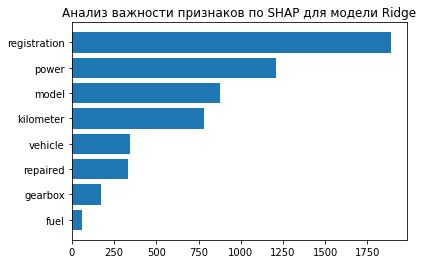

In [47]:
top_n = 10
plt.figure()
plt.barh(imp_r["feature"].head(top_n), imp_r["mean_abs_shap"].head(top_n))
plt.gca().invert_yaxis()
plt.title("Анализ важности признаков по SHAP для модели Ridge")
plt.show()


In [50]:
# LightGBM SHAP

lgbm_best = lgbm_random.best_estimator_

X_bg = X_train.sample(n=min(200, len(X_train)), random_state=RANDOM_STATE)

pre_l, Xt_shap, fn_l = get_transformed(lgbm_best, X_shap, num_features, cat_features)

Xt_shap = to_dense_float32(Xt_shap)

lgbm_est = lgbm_best.named_steps["model"]
explainer_l = shap.TreeExplainer(lgbm_est)
shap_l = explainer_l.shap_values(Xt_shap)

sv = np.asarray(shap_l[0] if isinstance(shap_l, list) else shap_l)
importance = np.abs(sv).mean(axis=0)

def normalize_feature_name(f):
    return f.split("__", 1)[1] if isinstance(f, str) and "__" in f else f

imp_1 = (pd.DataFrame({"feature": fn_l, "mean_abs_shap": importance})
         .assign(feature=lambda df: df["feature"].map(normalize_feature_name))
         .sort_values("mean_abs_shap", ascending=False)
         .reset_index(drop=True))

imp_1.head(10)

,feature,mean_abs_shap
0,registration_year,2405.285795
1,power,1276.550467
2,kilometer,630.641412
3,model,549.754555
4,vehicle_type,347.116075
5,repaired,337.395223
6,gearbox,108.111591
7,fuel_type,33.171429


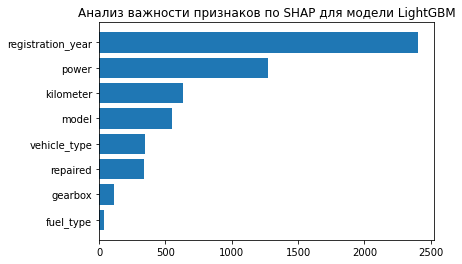

In [51]:
top_n = 10

plt.figure()
plt.barh(imp_1["feature"].head(top_n), imp_1["mean_abs_shap"].head(top_n))
plt.gca().invert_yaxis()
plt.title("Анализ важности признаков по SHAP для модели LightGBM")
plt.show()


In [52]:
def clean_feature_name(f):
    if isinstance(f, str) and "__" in f:
        return f.split("__", 1)[1]
    return f


ridge_df = imp_r.copy()
ridge_df["feature"] = ridge_df["feature"].map(clean_feature_name)
ridge_df = ridge_df.rename(columns={"mean_abs_shap": "ridge_mean_abs_shap"})


lgbm_df = imp_1.copy()
lgbm_df["feature"] = lgbm_df["feature"].map(clean_feature_name)
lgbm_df = lgbm_df.rename(columns={"mean_abs_shap": "lgbm_mean_abs_shap"})

ridge_df["feature"] = ridge_df["feature"].replace({"registration": "registration_year"})


cmp = (ridge_df.merge(lgbm_df, on="feature", how="outer")
              .fillna(0))

cmp["ridge_share_%"] = 100 * cmp["ridge_mean_abs_shap"] / (cmp["ridge_mean_abs_shap"].sum() + 1e-12)
cmp["lgbm_share_%"]  = 100 * cmp["lgbm_mean_abs_shap"]  / (cmp["lgbm_mean_abs_shap"].sum()  + 1e-12)

cmp = cmp.sort_values("lgbm_mean_abs_shap", ascending=False).reset_index(drop=True)

cmp.head(20)



,feature,ridge_mean_abs_shap,lgbm_mean_abs_shap,ridge_share_%,lgbm_share_%
0,registration_year,1889.491991,2405.285795,33.326552,42.286824
1,power,1207.672651,1276.550467,21.300733,22.442766
2,kilometer,784.862571,630.641412,13.843278,11.087174
3,model,876.919386,549.754555,15.466961,9.665119
4,vehicle_type,0.000000,347.116075,0.000000,6.102575
5,repaired,333.270237,337.395223,5.878166,5.931675
6,gearbox,174.338103,108.111591,3.074947,1.900687
7,fuel_type,0.000000,33.171429,0.000000,0.583180
8,vehicle,345.851048,0.000000,6.100064,0.000000
9,fuel,57.223448,0.000000,1.009298,0.000000


Обе модели подтверждают, что стоимость автомобиля прежде всего определяется годом регистрации, мощностью двигателя и пробегом.
Однако LightGBM делает более выраженный акцент на количественных характеристиках, что согласуется с его более высокой точностью предсказания.

# Итоговый вывод по проекту

## Цель проекта
Разработать модель машинного обучения для прогнозирования стоимости подержанных автомобилей с требованием:
**RMSE < 2500**.

---

## Этап 1. Подготовка данных

Были выполнены следующие шаги:

- Удалены неинформативные признаки:
  - `date_crawled`
  - `date_created`
  - `last_seen`
  - `number_of_pictures`
  - `postal_code`
  - `brand` (из-за корреляции с `model`)
- Ограничены диапазоны:
  - `registration_year`: 1990–2016
  - `power`: 40–400 л.с.
- Удалены записи с `price = 0`
- Заполнены пропуски значением `"unknown"`
- Удалены дубликаты
- Проведён EDA:
  - анализ распределений
  - анализ категориальных признаков
  - корреляционный анализ (PhiK)

---

## Этап 2. Построение моделей

Была реализована корректная ML-архитектура:

- Разделение на train/test
- Использование `Pipeline` и `ColumnTransformer`
- OneHotEncoder для категориальных признаков
- Масштабирование числовых признаков
- Подбор гиперпараметров через `GridSearchCV` и `RandomizedSearchCV`
- Контроль отсутствия data leakage

Рассмотрены модели:

1. **DummyRegressor** — наивный baseline  
2. **Ridge** — линейная модель  
3. **LightGBM** — бустинговая модель  

---

## Результаты

| Модель | Best CV RMSE |
|--------|-----------|
| Dummy | **4608** |
| Ridge | **2448** |
| LightGBM | **1668** |

Лучшая модель **LightGBM**: RMSE на тестовых данных - 1625, время предсказания - 2.7 сек.

Требование заказчика (**RMSE < 2500**) выполнено обеими обучаемыми моделями.

LightGBM показала:
- снижение ошибки на ~33% по сравнению с Ridge
- наилучшее качество предсказания

---

## Интерпретация моделей (SHAP)

Анализ важности признаков показал:

Основные факторы, влияющие на цену автомобиля:
1. **Год регистрации**
2. **Мощность двигателя**
3. **Пробег**

LightGBM делает более выраженный акцент на количественных характеристиках,
что объясняет её более высокую точность.

---

## Финальный вывод

- Модель **LightGBM** демонстрирует наилучшее качество прогнозирования.
- Ошибка RMSE = **1625**, что существенно ниже установленного порога.
- Модель интерпретируема (SHAP-анализ).
- Архитектура реализована без data leakage.

### Рекомендуется использовать LightGBM в качестве основной модели
для прогнозирования стоимости подержанных автомобилей.
